# Downloading waveforms for the 2004 M6 Parkfield earthquake with ObsPy and FDSN web services

This notebook is based on `tutorials/data-access-scripts/get_parkfield_waveforms_multisource.py`. It downloads waveforms for every
phase arrival of the 2004 M6 Parkfield earthquake (ComCat ID `nc30228270`).

The workflow uses two kinds of web services:

1. An **event** service (USGS ComCat) to find out what happened: where and when the
   earthquake was, and which stations recorded which phases (the "picks").
2. **Waveform** services (FDSN dataselect at SCEDC and NCEDC) to download the actual
   ground-motion time series around each pick.

FDSN (International Federation of Digital Seismograph Networks) defines standard
web-service APIs that most data centers implement:

| Service | Returns |
|---|---|
| `fdsnws/event/1/` | earthquake catalogs: QuakeML (XML), GeoJSON, text |
| `fdsnws/station/1/` | station metadata: StationXML, text |
| `fdsnws/dataselect/1/` | waveform data: miniSEED |

Because the APIs are the same everywhere, ObsPy's FDSN `Client` can talk to any of
these data centers with identical code. Only the name changes.

Key ObsPy objects used below:

```
Catalog -> Event -> Origin -> Arrival   (one per phase used in the location)
                 -> Pick                (the measured onset time)
Stream  -> Trace -> .data (numpy array), .stats (metadata)
UTCDateTime        a timestamp you can add or subtract seconds from
```

## Imports

In [1]:
import csv
import json
import os
import urllib.request

# read_events parses QuakeML (and many other catalog formats) into an
# obspy Catalog object.
from obspy import read, read_events
# Client is ObsPy's generic FDSN web-service client. Client("SCEDC") looks up
# the SCEDC base URL (https://service.scedc.caltech.edu) from ObsPy's built-in
# list; you can also pass a full URL for data centers not in that list.
from obspy.clients.fdsn import Client
# The FDSN services answer "nothing matched" with HTTP 204 (No Content);
# ObsPy turns that into this exception rather than returning an empty Stream.
from obspy.clients.fdsn.header import FDSNNoDataException

## Parameters

These replace the script's command-line options (`--outdir`, `--before`, `--after`,
`--ref`, `--max-km`). Change them and re-run the cells below.

`OUTDIR` defaults to `waveforms_nb` so the notebook doesn't overwrite the script's
`waveforms/` folder. `MAX_KM = 100` matches the 100 km plotted in the record section
(Step 7). With `MAX_KM = None` every arrival is downloaded (a few hundred requests,
which takes a while). Try `MAX_KM = 50` for a quick first run.

In [2]:
OUTDIR = "waveforms_nb"
BEFORE = 0.0      # seconds before the reference time to start
AFTER = 60.0      # seconds after the reference time to end
REF = "origin"   # "arrival" or "origin": time that BEFORE/AFTER are measured from
MAX_KM = 100      # only arrivals within this epicentral distance (None = all)

os.makedirs(OUTDIR, exist_ok=True)

## Constants

ComCat event IDs are the contributing network code plus that network's own ID.
`nc` is the Northern California Seismic System, which located this event.

The ComCat FDSN event service, given an `eventid` and `format=geojson`, returns a
"detail" document listing every product (origins, moment tensors, ShakeMaps, phase
data, ...) contributed for the event, with download URLs. Try opening `DETAIL_URL`
in a browser to see what it contains.

In [3]:
EVENTID = "nc30228270"
DETAIL_URL = ("https://earthquake.usgs.gov/fdsnws/event/1/query"
              f"?eventid={EVENTID}&format=geojson")
# Networks whose data are archived at SCEDC (Southern California); Parkfield
# is in central California, so most stations belong to NCEDC networks
# (NC, BK, BP, ...).
SCEDC_NETS = {"CI", "AZ", "ZY"}
# Approximate km per degree of great-circle arc. QuakeML stores epicentral
# distance in degrees.
DEG2KM = 111.19
print(DETAIL_URL)

https://earthquake.usgs.gov/fdsnws/event/1/query?eventid=nc30228270&format=geojson


## Step 1: get the phase picks from ComCat

The `phase-data` product contains the origin plus all picks and arrivals. Several
networks may contribute one, so we pick the `nc` copy, which belongs to the
authoritative location. The QuakeML file is saved locally so it can be inspected
later and the run is reproducible.

Tip: for plain catalog searches (by time, region, magnitude) you would normally use
`Client("USGS").get_events(...)` instead of building URLs by hand. Here we go through
the GeoJSON detail because the phase-data product is only reachable that way.

In [4]:
def fetch_phases(outdir):
    """Download the nc phase-data QuakeML and return the parsed event."""
    # Ask ComCat for the event detail (GeoJSON = plain JSON).
    with urllib.request.urlopen(DETAIL_URL) as f:
        detail = json.load(f)
    products = detail["properties"]["products"]["phase-data"]
    nc = next(p for p in products if p["source"] == "nc")
    # Each product lists its files under "contents".
    path = os.path.join(outdir, f"{EVENTID}_phases.xml")
    urllib.request.urlretrieve(nc["contents"]["quakeml.xml"]["url"], path)
    # read_events returns a Catalog (a list of Events); this file holds only
    # one event, so take element [0].
    return read_events(path)[0]


event = fetch_phases(OUTDIR)
print(event)

Event:	2004-09-28T17:15:24.250000Z | +35.818, -120.366 | 5.97 Mw | manual

	            resource_id: ResourceIdentifier(id="quakeml:nc.anss.org/Event/NC/30228270")
	             event_type: 'earthquake'
	          creation_info: CreationInfo(agency_id='NC', creation_time=UTCDateTime(2013, 6, 18, 20, 47, 40), version='1')
	    preferred_origin_id: ResourceIdentifier(id="quakeml:nc.anss.org/Origin/NC/5720684")
	 preferred_magnitude_id: ResourceIdentifier(id="quakeml:nc.anss.org/Netmag/NC/4386109")
	                   ---------
	                  picks: 241 Elements
	             amplitudes: 498 Elements
	                origins: 1 Elements
	             magnitudes: 3 Elements
	     station_magnitudes: 637 Elements


## Step 2: explore the event

An Event can carry several Origins (solutions from different methods or agencies);
`preferred_origin()` is the one the catalog considers best. Some files don't mark a
preferred origin, so we fall back to the first.

In QuakeML, objects reference each other by `resource_id` (like a foreign key). Each
Arrival has a `pick_id` pointing at a Pick, so we build a lookup table from
`resource_id` to Pick.

In [5]:
origin = event.preferred_origin() or event.origins[0]
picks = {p.resource_id: p for p in event.picks}

print("Origin time:", origin.time)
print("Location:   ", origin.latitude, origin.longitude, f"{origin.depth / 1000:.1f} km")
print("Picks:      ", len(event.picks))
print("Arrivals:   ", len(origin.arrivals))

Origin time: 2004-09-28T17:15:24.250000Z
Location:    35.8181667 -120.366 8.1 km
Picks:       241
Arrivals:    241


Look at one arrival and its pick. The arrival adds location-specific information to
the pick: phase name, distance (in degrees), residual, weight, ...

`pick.waveform_id` is a `WaveformStreamID`: the network, station, location and
channel the pick was made on. Its SEED string looks like `NC.PMM..HHZ`: network NC,
station PMM, empty location, channel HHZ (H = high sample rate, H = high-gain
seismometer, Z = vertical).

In [6]:
arr = origin.arrivals[0]
pick = picks[arr.pick_id]
print(arr)
print(pick)
print("SEED id:", pick.waveform_id.get_seed_string())
print(f"Distance: {arr.distance:.3f} deg = {arr.distance * DEG2KM:.1f} km")

Arrival
	     resource_id: ResourceIdentifier(id="quakeml:nc.anss.org/AssocArO/NC/68325319")
	         pick_id: ResourceIdentifier(id="quakeml:nc.anss.org/Arrival/NC/68325319")
	           phase: 'P'
	 time_correction: -0.12
	         azimuth: 37.0
	        distance: 0.01622
	   takeoff_angle: 166.0
	   time_residual: -0.02
	     time_weight: 0.13
	   creation_info: CreationInfo(agency_id='NC', creation_time=UTCDateTime(2007, 9, 25, 23, 55, 47))
Pick
	       resource_id: ResourceIdentifier(id="quakeml:nc.anss.org/Arrival/NC/68325319")
	              time: UTCDateTime(2004, 9, 28, 17, 15, 25, 930000)
	       waveform_id: WaveformStreamID(network_code='NC', station_code='PGH', channel_code='EHZ', location_code='')
	             onset: 'impulsive'
	          polarity: 'positive'
	   evaluation_mode: 'manual'
	 evaluation_status: 'final'
	     creation_info: CreationInfo(agency_id='NC', creation_time=UTCDateTime(2007, 9, 25, 23, 55, 47))
SEED id: NC.PGH..EHZ
Distance: 0.016 deg = 1.8 km


## Step 3: download one waveform

This is the core FDSN dataselect request. The arguments are network, station,
location, channel, start time and end time. The times are `UTCDateTime` objects, and
adding or subtracting a number shifts them by that many seconds.

FDSN services spell an empty location code as `"--"`. The result is an ObsPy
`Stream`: a list of `Trace` objects, one per contiguous chunk of data.

Add `attach_response=True` if you plan to remove the instrument response later with
`st.remove_response()`.

In [7]:
wid = pick.waveform_id
center = "SCEDC" if wid.network_code in SCEDC_NETS else "NCEDC"
client = Client(center)
st = client.get_waveforms(wid.network_code, wid.station_code,
                          wid.location_code or "--", wid.channel_code,
                          pick.time - 10, pick.time + 60)
print(st)

1 Trace(s) in Stream:
NC.PGH..EHZ | 2004-09-28T17:15:15.930000Z - 2004-09-28T17:16:25.920000Z | 100.0 Hz, 7000 samples


Every Trace has a `.stats` header with network, station, location, channel,
starttime, sampling_rate, npts, ... and the samples are in `.data` as a numpy array.

               network: NC
               station: PGH
              location: 
               channel: EHZ
             starttime: 2004-09-28T17:15:15.930000Z
               endtime: 2004-09-28T17:16:25.920000Z
         sampling_rate: 100.0
                 delta: 0.01
                  npts: 7000
                 calib: 1.0
_fdsnws_dataselect_url: https://service.ncedc.org/fdsnws/dataselect/1/query
               _format: MSEED
                 mseed: AttribDict({'dataquality': 'D', 'number_of_records': 2, 'encoding': 'STEIM2', 'byteorder': '>', 'record_length': 4096, 'filesize': 8192})
            processing: ['ObsPy 1.4.1: trim(endtime=UTCDateTime(2004, 9, 28, 17, 16, 25, 930000)::fill_value=None::nearest_sample=True::pad=False::starttime=UTCDateTime(2004, 9, 28, 17, 15, 15, 930000))']
[-116 -118 -117 -116 -115 -117 -119 -117 -116 -115]


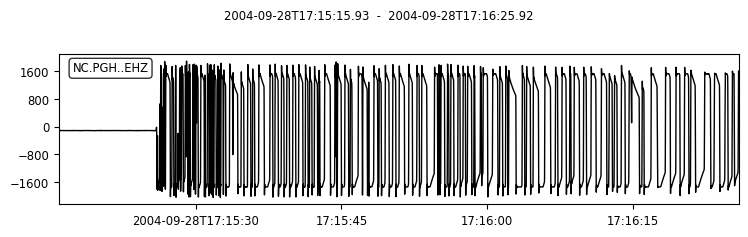

In [8]:
tr = st[0]
print(tr.stats)
print(tr.data[:10])
st.plot();

## Step 4: download every arrival

The pick's location code does not always match what the archive uses, so if the
exact one fails we retry with the wildcard `"*"` (any location). `get_waveforms` also
accepts `?` wildcards and comma-separated lists in each field.

The data center that normally archives the network is tried first (CI to SCEDC,
everything else to NCEDC), then the other. For many channels at once,
`Client.get_waveforms_bulk()` is much faster than a loop of single requests.

In [9]:
def get_waveform(clients, order, wid, t0, t1):
    """Try each data center and location code; return (stream, center, loc)."""
    locs = [wid.location_code or "--"]
    if locs[0] != "*":
        locs.append("*")
    for name in order:
        for loc in locs:
            try:
                st = clients[name].get_waveforms(
                    wid.network_code, wid.station_code, loc,
                    wid.channel_code, t0, t1)
            except FDSNNoDataException:
                # No data at this center for this request; try the next one.
                continue
            if len(st):
                return st, name, loc
    return None, None, None

Create each client once and reuse it. Creating a Client contacts the server to
discover which services it offers, so don't create one per request.

A gap in the data (telemetry dropout, etc.) makes the server return several Traces for
one channel. `merge(method=1)` joins them into one Trace per channel; any remaining
gaps become masked (`numpy.ma`) values. miniSEED cannot store masked arrays, so if
`merge()` left gaps, `split()` turns the Stream back into gap-free Traces before
writing.

In [10]:
clients = {"SCEDC": Client("SCEDC"), "NCEDC": Client("NCEDC")}

rows = []
for arr in origin.arrivals:
    if MAX_KM and arr.distance * DEG2KM > MAX_KM:
        continue
    pick = picks[arr.pick_id]
    wid = pick.waveform_id
    # The phase label (P, S, Pn, ...) may be on the arrival, the pick, or
    # missing entirely; "X" marks unknown.
    phase = arr.phase or pick.phase_hint or "X"
    order = (["SCEDC", "NCEDC"] if wid.network_code in SCEDC_NETS
             else ["NCEDC", "SCEDC"])
    ref = pick.time if REF == "arrival" else origin.time
    t0, t1 = ref - BEFORE, ref + AFTER
    st, center, loc = get_waveform(clients, order, wid, t0, t1)

    row = {"id": wid.get_seed_string(), "phase": phase,
           "arrival": str(pick.time), "distance_deg": arr.distance,
           "center": center or "", "loc_used": loc or "", "file": "",
           "traces": 0}
    if st is None:
        print(f"no data  {row['id']} {phase}")
    else:
        st.merge(method=1)
        # Use the location code the server actually returned, which may
        # differ from the pick's if the "*" fallback was used.
        fname = (f"{wid.network_code}.{wid.station_code}."
                 f"{st[0].stats.location}.{wid.channel_code}.{phase}"
                 f".{pick.time.strftime('%H%M%S')}.mseed")
        path = os.path.join(OUTDIR, fname)
        if any(hasattr(tr.data, "mask") for tr in st):
            st = st.split()
        st.write(path, format="MSEED")
        row.update(file=fname, traces=len(st))
        print(f"{center:5s}    {row['id']} {phase} -> {fname}")
    rows.append(row)

NCEDC    NC.PGH..EHZ P -> NC.PGH..EHZ.P.171525.mseed
NCEDC    NC.PHA..EHZ P -> NC.PHA..EHZ.P.171526.mseed
NCEDC    NC.PHF..EHZ P -> NC.PHF..EHZ.P.171526.mseed
NCEDC    NC.PSR..EHZ P -> NC.PSR..EHZ.P.171526.mseed
NCEDC    NC.PCHC..HNZ P -> NC.PCHC..HNZ.P.171527.mseed
NCEDC    NC.PMC..SHZ P -> NC.PMC..SHZ.P.171527.mseed
NCEDC    NC.PHOB..EHZ P -> NC.PHOB..EHZ.P.171527.mseed
NCEDC    NC.PMR..EHZ P -> NC.PMR..EHZ.P.171527.mseed
NCEDC    NC.PCA..EHZ P -> NC.PCA..EHZ.P.171527.mseed
NCEDC    NC.PWK..EHZ P -> NC.PWK..EHZ.P.171527.mseed
NCEDC    NC.PAG..EHZ P -> NC.PAG..EHZ.P.171527.mseed
NCEDC    BP.JCNB..DP1 P -> BP.JCNB..DP1.P.171527.mseed
NCEDC    NC.PFR.10.HV1 P -> NC.PFR.10.HV1.P.171527.mseed
NCEDC    NC.PST..EHZ P -> NC.PST..EHZ.P.171528.mseed
NCEDC    BP.VCAB..DP1 P -> BP.VCAB..DP1.P.171528.mseed
NCEDC    NC.PVC..EHZ P -> NC.PVC..EHZ.P.171528.mseed
NCEDC    BP.MMNB..DP1 P -> BP.MMNB..DP1.P.171528.mseed
NCEDC    NC.PMM..EHZ P -> NC.PMM..EHZ.P.171528.mseed
NCEDC    NC.PBS..EHZ P -> NC.PBS

## Step 5: write a summary

The summary records which data center served each channel, so missing data can be
followed up later.

In [11]:
with open(os.path.join(OUTDIR, "summary.csv"), "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0]))
    w.writeheader()
    w.writerows(rows)
got = sum(1 for r in rows if r["file"])
print(f"{got}/{len(rows)} arrivals with data; see "
      f"{os.path.join(OUTDIR, 'summary.csv')}")

62/62 arrivals with data; see waveforms_nb/summary.csv


## Step 6: read the files back

`obspy.read` accepts wildcards and returns everything as one Stream.

In [12]:
st_all = read(os.path.join(OUTDIR, "*.mseed"))
print(st_all.__str__(extended=False))

62 Trace(s) in Stream:

BP.CCRB..DP1 | 2004-09-28T17:15:24.253689Z - 2004-09-28T17:16:24.249689Z | 250.0 Hz, 15000 samples
...
(60 other traces)
...
NC.PWM..EHZ | 2004-09-28T17:15:24.250000Z - 2004-09-28T17:16:24.240000Z | 100.0 Hz, 6000 samples

[Use "print(Stream.__str__(extended=True))" to print all Traces]


## Step 7: plot a record section

A record section stacks the waveforms by distance from the earthquake, so you can
watch the P wave move outward across the network. Each row is one downloaded arrival
within 100 km (nearest on top), plotted against time after the origin. The ComCat
pick is marked in **blue**. **SCEDC** waveforms are **orange** and NCEDC waveforms
are gray.

Before plotting, each trace is cleaned up with standard ObsPy processing:
`detrend` removes the offset and any drift, `taper` smooths the ends, and a 1 Hz
`highpass` filter removes long-period noise (`zerophase=True` filters forward and
backward so the onsets don't shift in time). Each trace is then normalized to its
own peak, because amplitudes vary by orders of magnitude between stations.

This follows `plot_record_section.py`, but uses the `rows` and `origin` already in
memory instead of reading `summary.csv` and the QuakeML file again.

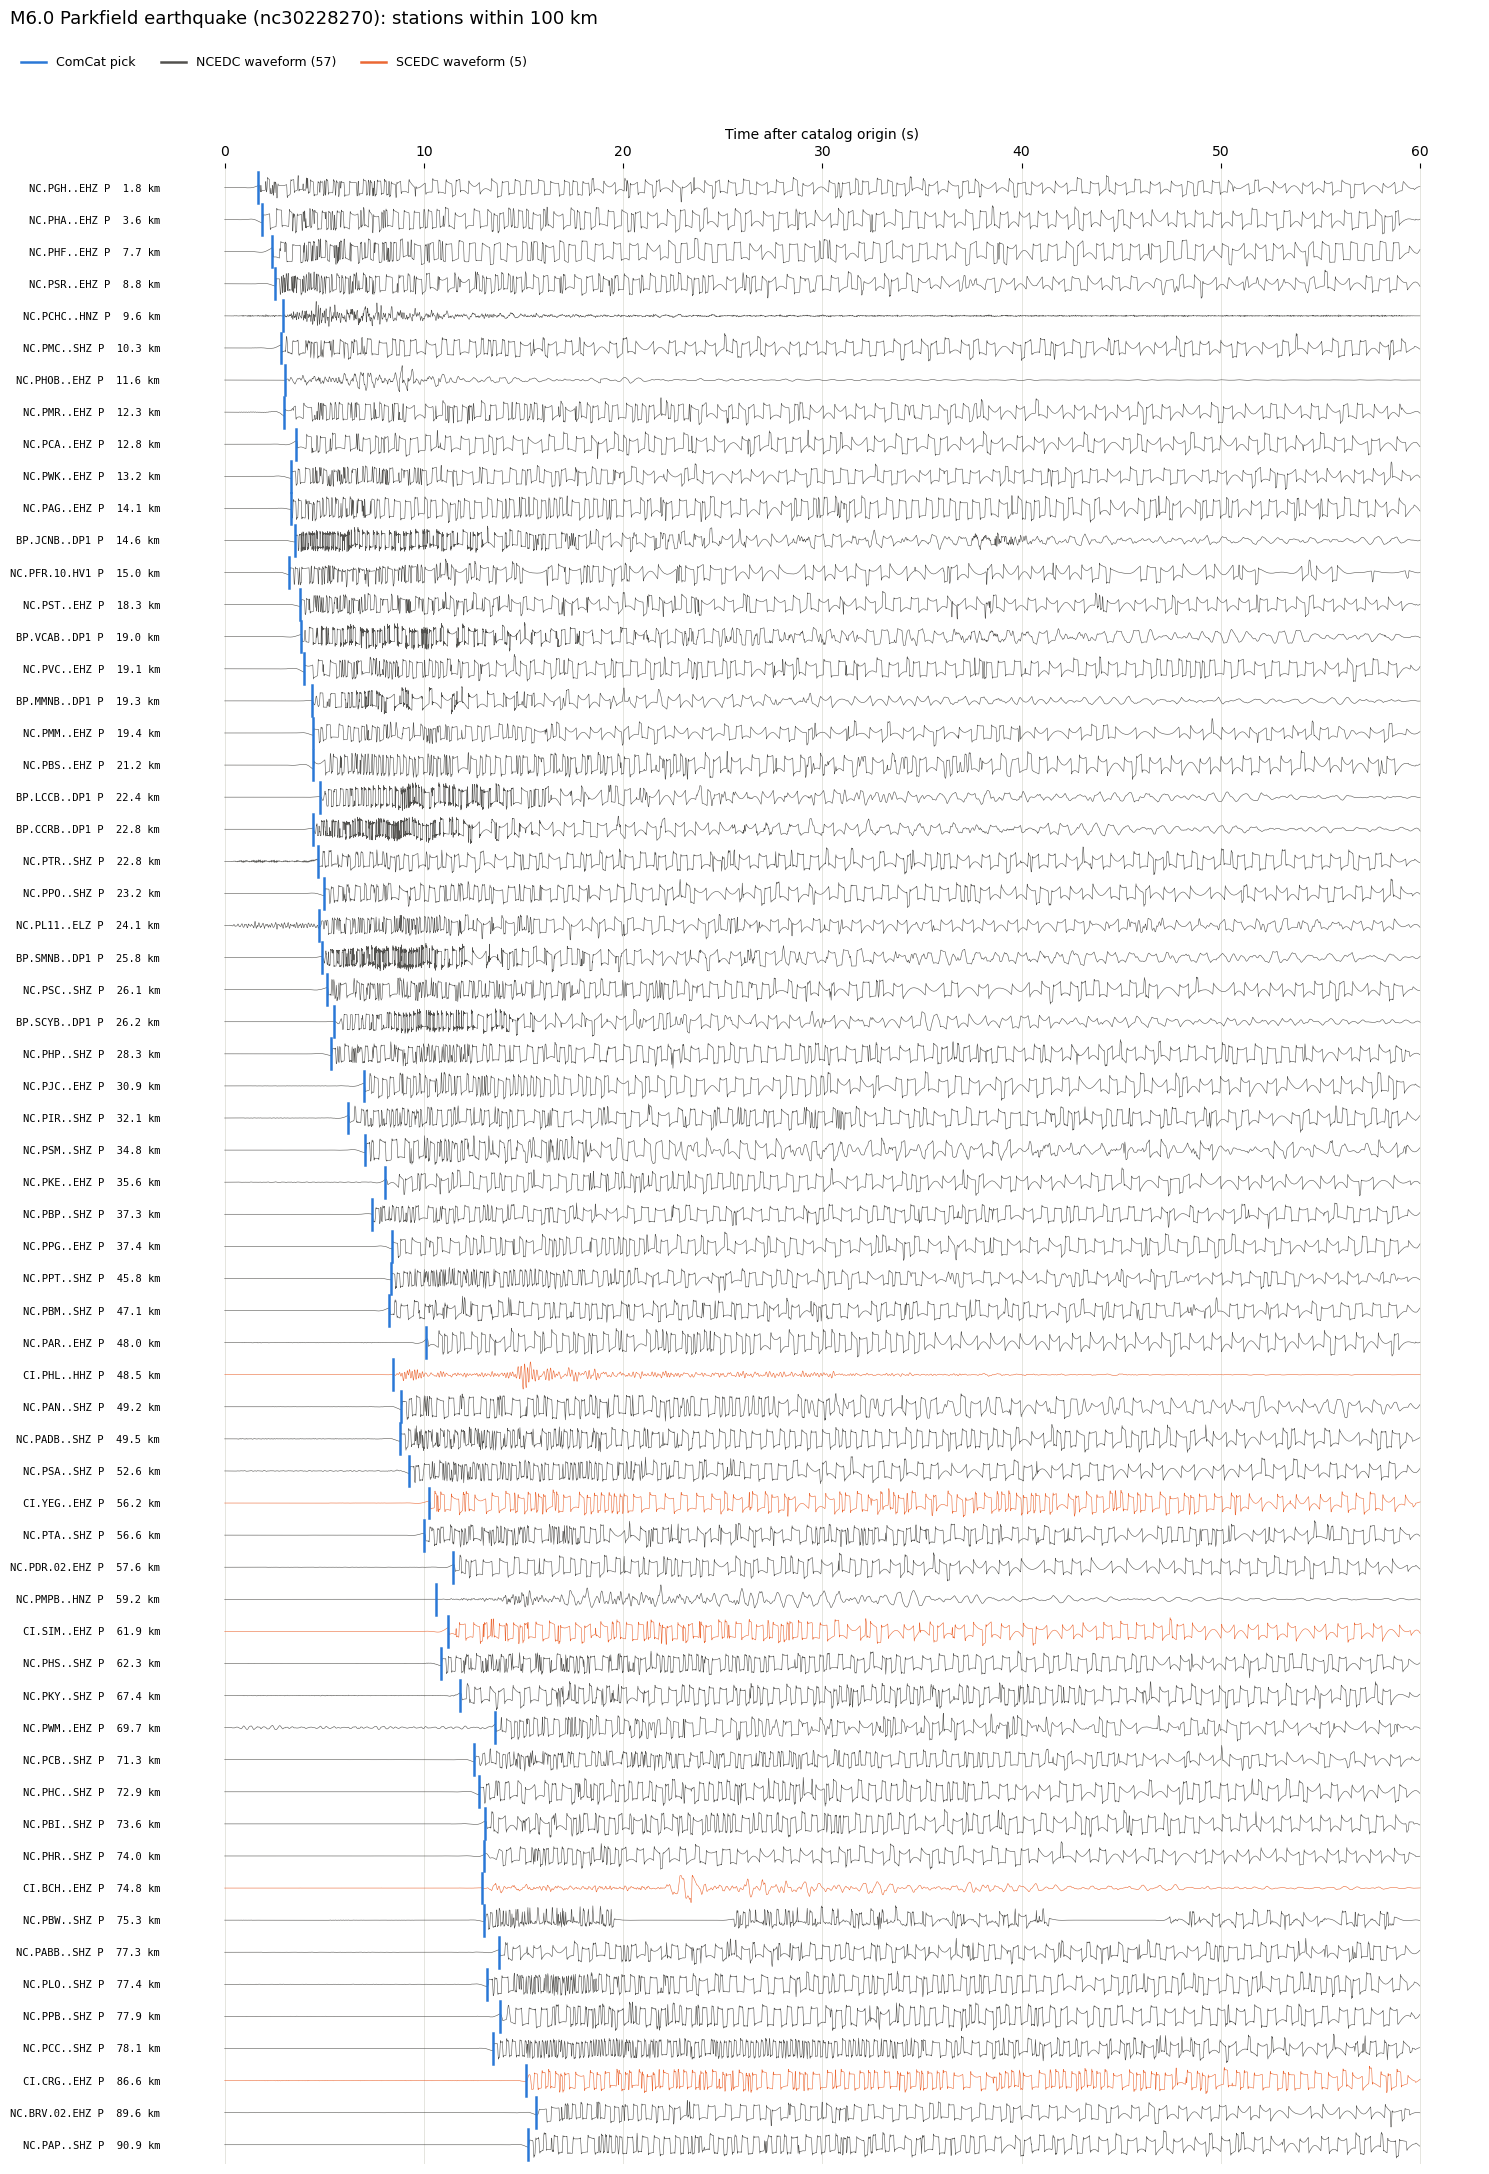

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from obspy import UTCDateTime

PLOT_KM = 100     # only plot stations within this epicentral distance
HIGHPASS = 1.0    # highpass corner in Hz (0 to disable)
TRACE = {"NCEDC": "#52514e", "SCEDC": "#eb6834"}   # gray, orange
PICK = "#2a78d6"                                   # blue

# Keep arrivals that have a file and are within PLOT_KM, nearest first.
sec = [dict(r, km=r["distance_deg"] * DEG2KM) for r in rows if r["file"]]
sec = sorted((r for r in sec if r["km"] <= PLOT_KM), key=lambda r: r["km"])

fig, ax = plt.subplots(figsize=(15, 0.32 * len(sec) + 2))
for i, r in enumerate(sec):
    parts = []
    # split() keeps gaps as gaps instead of drawing a line across them.
    for tr in read(os.path.join(OUTDIR, r["file"])).split():
        tr.detrend("demean"); tr.detrend("linear"); tr.taper(0.02)
        if HIGHPASS:
            tr.filter("highpass", freq=HIGHPASS, corners=4, zerophase=True)
        # tr.times(reftime=...) gives each sample's time in seconds after
        # the origin, so every row shares the same time axis.
        parts.append((tr.times(reftime=origin.time), tr.data.astype(float)))
    peak = max(np.abs(y).max() for _, y in parts) or 1.0
    for t, y in parts:
        # Rows count downward, so subtract to keep positive motion pointing up.
        ax.plot(t, i - y / peak * 0.45, color=TRACE[r["center"]], lw=0.4,
                zorder=3 if r["center"] == "SCEDC" else 2)
    tp = UTCDateTime(r["arrival"]) - origin.time
    ax.plot([tp] * 2, [i - 0.48, i + 0.48], color=PICK, lw=1.8, zorder=4)

ax.set_yticks(np.arange(len(sec)))
ax.set_yticklabels([f"{r['id']} {r['phase']}  {r['km']:.1f} km" for r in sec],
                   fontsize=7.5, family="monospace")
ax.set_ylim(len(sec) - 0.4, -0.6)
ax.set_xlabel("Time after catalog origin (s)")
ax.xaxis.set_label_position("top"); ax.xaxis.tick_top()
ax.grid(True, axis="x", color="#e1e0d9", lw=0.6)
ax.set_axisbelow(True)
for side in ax.spines:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)

n = {c: sum(r["center"] == c for r in sec) for c in TRACE}
# Put the title and legend above the axes so they never cover a trace.
H = fig.get_figheight()
fig.suptitle(f"M6.0 Parkfield earthquake ({EVENTID}): stations within {PLOT_KM} km",
             x=0.01, y=1 - 0.15 / H, ha="left", va="top", fontsize=13)
fig.legend([Line2D([], [], color=PICK, lw=1.8)]
           + [Line2D([], [], color=c, lw=1.8) for c in TRACE.values()],
           ["ComCat pick"] + [f"{k} waveform ({n[k]})" for k in TRACE],
           loc="upper left", bbox_to_anchor=(0.01, 1 - 0.5 / H),
           ncol=3, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.85 / H))   # leave room for the legend row
plt.show()